<a href="https://colab.research.google.com/github/VrgiPramudya/computer-vision/blob/main/Jobsheet_05_Galih_Virgi_Pramudya_Visi_Komputer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Persiapan Lingkungan

In [1]:
# === Persiapan 1: instalasi pustaka (Colab sudah memiliki torch dan torchvision) ===
!pip install -q transformers

# === Persiapan 2: impor, cek GPU, seed, dan konfigurasi ===
import os, time, random, json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu" # Jika tanpa GPU: jalankan versi diperkecil

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "-", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")

CFG = dict(
    IMG = 128 if CEPAT else 256,      # ukuran sisi citra (piksel)
    N_TRAIN = 320 if CEPAT else 2000, # jumlah citra latih
    N_TEST = 100 if CEPAT else 500,   # jumlah citra uji
    BATCH = 16,
    EP_UNET = 6 if CEPAT else 15,
    EP_DLV3 = 2 if CEPAT else 6,
    EP_SEGF = 3 if CEPAT else 6,
    BASE_CH = 16 if CEPAT else 32     # lebar kanal U-Net
)

print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {} # catatan waktu tiap bagian

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
Perangkat: cuda - Tesla T4
Mode: PENUH (GPU) {'IMG': 256, 'N_TRAIN': 2000, 'N_TEST': 500, 'BATCH': 16, 'EP_UNET': 15, 'EP_DLV3': 6, 'EP_SEGF': 6, 'BASE_CH': 32}


#Praktikum D1 (Unduh Data & Pemrosesan)

Subset sudah tersedia di data/pet_subset
Citra latih: 2000 | citra uji: 500 | waktu 3.9 detik


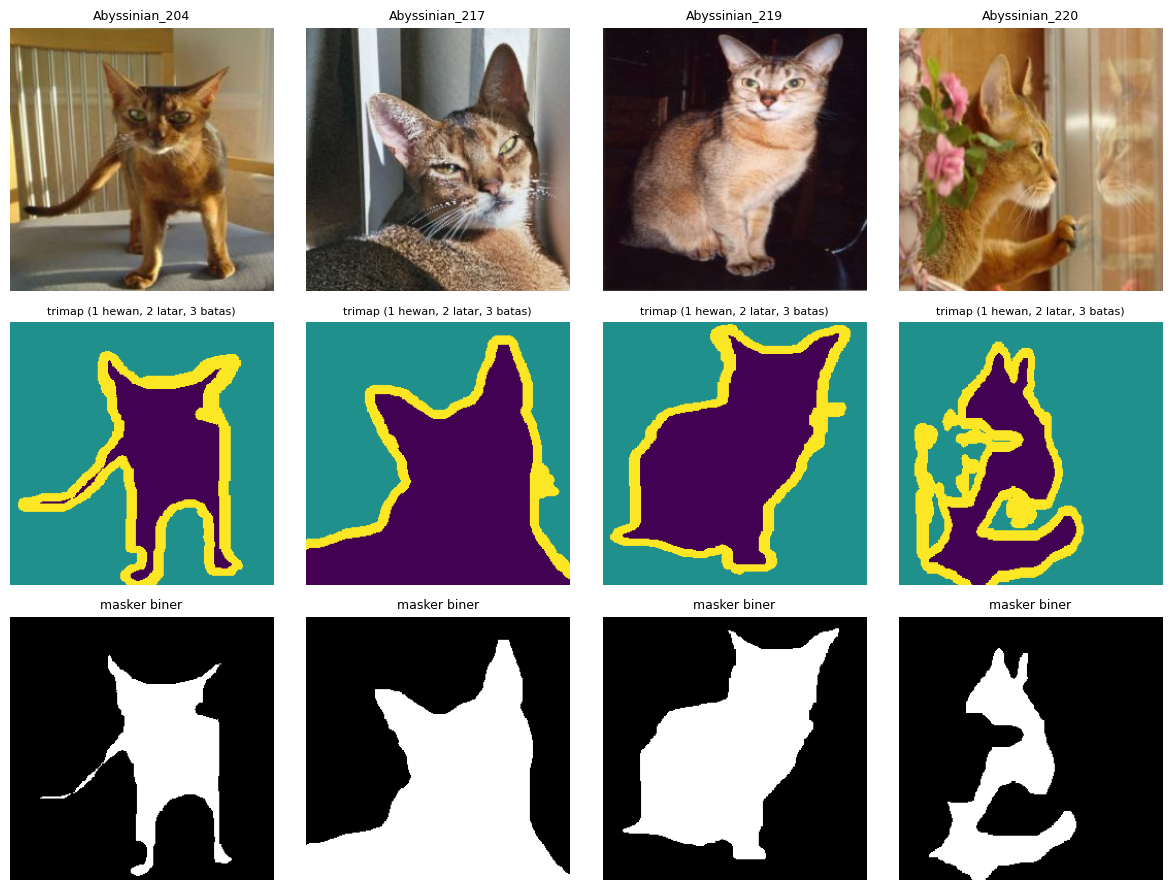

In [3]:
# === D1.1 Unduh subset Oxford-IIIT Pet dari server resmi VGG ===
import tarfile, urllib.request
URL_IMG = "https://thor.robots.ox.ac.uk/pets/images.tar.gz"
URL_ANN = "https://thor.robots.ox.ac.uk/pets/annotations.tar.gz"

def ambil_subset_pet(root="data/pet_subset", n_train=480, n_test=120):
    os.makedirs(f"{root}/images", exist_ok=True)
    os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve(URL_ANN, ann)

    split, trimaps = {}, {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/trainval.txt") or m.name.endswith("annotations/test.txt"):
                s = "train" if "trainval" in m.name else "test"
                for line in t.extractfile(m).read().decode().splitlines():
                    if line.strip():
                        split[line.split()[0]] = s
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()

    def hitung():
        ada = [f[:-4] for f in os.listdir(f"{root}/images") if f.endswith(".jpg")]
        return (sorted(i for i in ada if split.get(i) == "train"),
                sorted(i for i in ada if split.get(i) == "test"))

    tr, te = hitung()
    if len(tr) >= n_train and len(te) >= n_test:
        print("Subset sudah tersedia di", root)
        return tr[:n_train], te[:n_test]

    with urllib.request.urlopen(URL_IMG) as resp, tarfile.open(fileobj=resp, mode="r:gz") as t:
        for m in t:
            nama = os.path.basename(m.name)
            if not nama.endswith(".jpg"): continue
            iid = nama[:-4]; s = split.get(iid)
            if iid not in trimaps or s is None: continue
            if (s == "train" and len(tr) >= n_train) or (s == "test" and len(te) >= n_test): continue

            with open(f"{root}/images/{nama}", "wb") as f:
                f.write(t.extractfile(m).read())
            with open(f"{root}/trimaps/{iid}.png", "wb") as f:
                f.write(trimaps[iid])

            (tr if s == "train" else te).append(iid)
            if len(tr) >= n_train and len(te) >= n_test: break

    tr, te = hitung()
    return tr[:n_train], te[:n_test]

t0 = time.time()
ROOT = "data/pet_subset"
ID_TRAIN, ID_TEST = ambil_subset_pet(ROOT, CFG["N_TRAIN"], CFG["N_TEST"])
print(f"Citra latih: {len(ID_TRAIN)} | citra uji: {len(ID_TEST)} | waktu {time.time()-t0:.1f} detik")

# === D1.2 Dataset PyTorch ===
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def muat_pasangan(iid, size):
    img = Image.open(f"{ROOT}/images/{iid}.jpg").convert("RGB").resize((size, size), Image.BILINEAR)
    tri = Image.open(f"{ROOT}/trimaps/{iid}.png").resize((size, size), Image.NEAREST)
    return np.array(img), np.array(tri)

class PetSegDataset(torch.utils.data.Dataset):
    def __init__(self, ids, size, augment=False):
        pairs = [muat_pasangan(i, size) for i in ids]
        self.img = torch.from_numpy(np.stack([p[0] for p in pairs])).permute(0, 3, 1, 2)
        self.tri = torch.from_numpy(np.stack([p[1] for p in pairs]))
        self.augment = augment

    def __len__(self): return len(self.img)

    def __getitem__(self, i):
        x = self.img[i].float() / 255.0
        tri = self.tri[i]
        y = (tri == 1).float().unsqueeze(0) # 1 = hewan, 0 = latar
        valid = (tri != 3).float().unsqueeze(0) # abaikan piksel batas

        if self.augment and random.random() < 0.5: # augmentasi horizontal flip
            x, y, valid = x.flip(-1), y.flip(-1), valid.flip(-1)
        return (x - MEAN) / STD, y, valid

ds_train = PetSegDataset(ID_TRAIN, CFG["IMG"], augment=True)
ds_test = PetSegDataset(ID_TEST, CFG["IMG"], augment=False)
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=CFG["BATCH"], shuffle=True)
dl_test = torch.utils.data.DataLoader(ds_test, batch_size=CFG["BATCH"], shuffle=False)
WAKTU["D1 data"] = time.time() - t0

# === D1.3 Visualisasi ===
def denorm(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()

fig, ax = plt.subplots(3, 4, figsize=(12,9))
for k in range(4):
    x, y, v = ds_test[k]
    ax[0, k].imshow(denorm(x)); ax[0, k].set_title(ID_TEST[k], fontsize=9)
    ax[1, k].imshow(ds_test.tri[k], cmap="viridis", vmin=1, vmax=3)
    ax[1, k].set_title("trimap (1 hewan, 2 latar, 3 batas)", fontsize=8)
    ax[2, k].imshow(y[0], cmap="gray"); ax[2, k].set_title("masker biner", fontsize=9)
    for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_dl_contoh_data.png", dpi=120); plt.show()

#Praktikum D2 (Membangun & Latih U-Net)

[U-Net (dari nol)] epoch 1/15 loss latih 0.9131 loss uji 1.0423 (50s)
[U-Net (dari nol)] epoch 2/15 loss latih 0.7507 loss uji 0.8429 (99s)
[U-Net (dari nol)] epoch 3/15 loss latih 0.6702 loss uji 0.6319 (149s)
[U-Net (dari nol)] epoch 4/15 loss latih 0.6202 loss uji 0.6528 (199s)
[U-Net (dari nol)] epoch 5/15 loss latih 0.5601 loss uji 0.5521 (249s)
[U-Net (dari nol)] epoch 6/15 loss latih 0.5247 loss uji 0.4831 (299s)
[U-Net (dari nol)] epoch 7/15 loss latih 0.4794 loss uji 0.4697 (349s)
[U-Net (dari nol)] epoch 8/15 loss latih 0.4425 loss uji 0.4086 (399s)
[U-Net (dari nol)] epoch 9/15 loss latih 0.4350 loss uji 0.3740 (449s)
[U-Net (dari nol)] epoch 10/15 loss latih 0.4021 loss uji 0.3680 (499s)
[U-Net (dari nol)] epoch 11/15 loss latih 0.3767 loss uji 0.3767 (550s)
[U-Net (dari nol)] epoch 12/15 loss latih 0.3586 loss uji 0.3607 (600s)
[U-Net (dari nol)] epoch 13/15 loss latih 0.3397 loss uji 0.3762 (650s)
[U-Net (dari nol)] epoch 14/15 loss latih 0.3366 loss uji 0.3798 (700s)
[U-

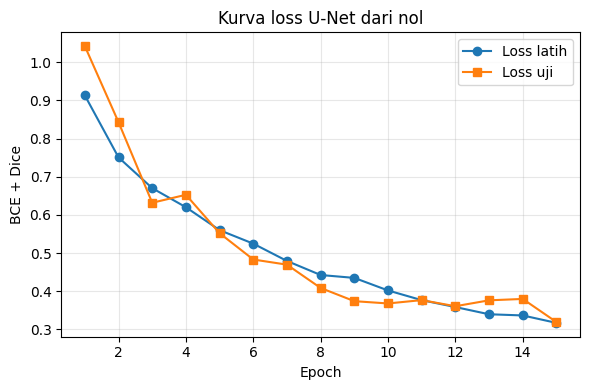

In [5]:
 # === D2.1 Arsitektur U-Net kecil ===
class DoubleConv(nn.Sequential):
    def __init__(self, cin, cout):
        super().__init__(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=16):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.enc = nn.ModuleList([DoubleConv(in_ch, c[0])] + [DoubleConv(c[i], c[i+1]) for i in range(4)])
        self.up = nn.ModuleList([nn.ConvTranspose2d(c[i+1], c[i], 2, stride=2) for i in reversed(range(4))])
        self.dec = nn.ModuleList([DoubleConv(c[i]*2, c[i]) for i in reversed(range(4))])
        self.head = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        skips = []
        for i, blk in enumerate(self.enc):
            x = blk(x if i == 0 else F.max_pool2d(x, 2))
            skips.append(x)
        x = skips.pop() # bottleneck
        for up, dec in zip(self.up, self.dec):
            x = up(x)
            x = dec(torch.cat([x, skips.pop()], dim=1)) # skip connection
        return self.head(x)

unet = UNet(base=CFG["BASE_CH"]).to(DEVICE)

# === D2.2 Loss BCE + Dice & Pelatihan ===
def bce_dice_loss(logit, y, valid, w_dice=1.0, eps=1.0):
    bce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    bce = (bce * valid).sum() / valid.sum().clamp_min(1)
    p = torch.sigmoid(logit) * valid
    inter = (p * y * valid).sum(dim=(1, 2, 3))
    dice = 1 - (2 * inter + eps) / (p.sum(dim=(1, 2, 3)) + (y * valid).sum(dim=(1, 2, 3)) + eps)
    return bce + w_dice * dice.mean()

def latih(model, forward, epochs, lr, nama, param_groups=None):
    opt = torch.optim.AdamW(param_groups or model.parameters(), lr=lr, weight_decay=1e-4)
    riwayat = {"train": [], "test": []}
    t0 = time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y, v in dl_train:
            x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
            loss = bce_dice_loss(forward(model, x), y, v)
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(x)

        model.eval(); tot_te = 0
        with torch.no_grad():
            for x, y, v in dl_test:
                x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
                tot_te += bce_dice_loss(forward(model, x), y, v).item() * len(x)

        riwayat["train"].append(tot / len(ds_train))
        riwayat["test"].append(tot_te / len(ds_test))
        print(f"[{nama}] epoch {ep+1}/{epochs} loss latih {riwayat['train'][-1]:.4f} loss uji {riwayat['test'][-1]:.4f} ({time.time()-t0:.0f}s)")
    WAKTU[nama] = time.time() - t0
    return riwayat

fwd_unet = lambda m, x: m(x)
set_seed(42)
hist_unet = latih(unet, fwd_unet, CFG["EP_UNET"], 1e-3, "U-Net (dari nol)")

# === D2.3 Kurva loss U-Net ===
plt.figure(figsize=(6, 4))
ep = range(1, len(hist_unet["train"]) + 1)
plt.plot(ep, hist_unet["train"], "o-", label="Loss latih")
plt.plot(ep, hist_unet["test"], "s-", label="Loss uji")
plt.xlabel("Epoch"); plt.ylabel("BCE + Dice"); plt.title("Kurva loss U-Net dari nol"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d2_kurva_unet.png", dpi=120); plt.show()

#Praktikum D3 (Metrik Evaluasi & Prediksi U-Net)

{'IoU hewan': 0.8206, 'IoU latar': 0.8979, 'mIoU': 0.8592, 'Dice': 0.9014, 'PixelAcc': 0.9304}


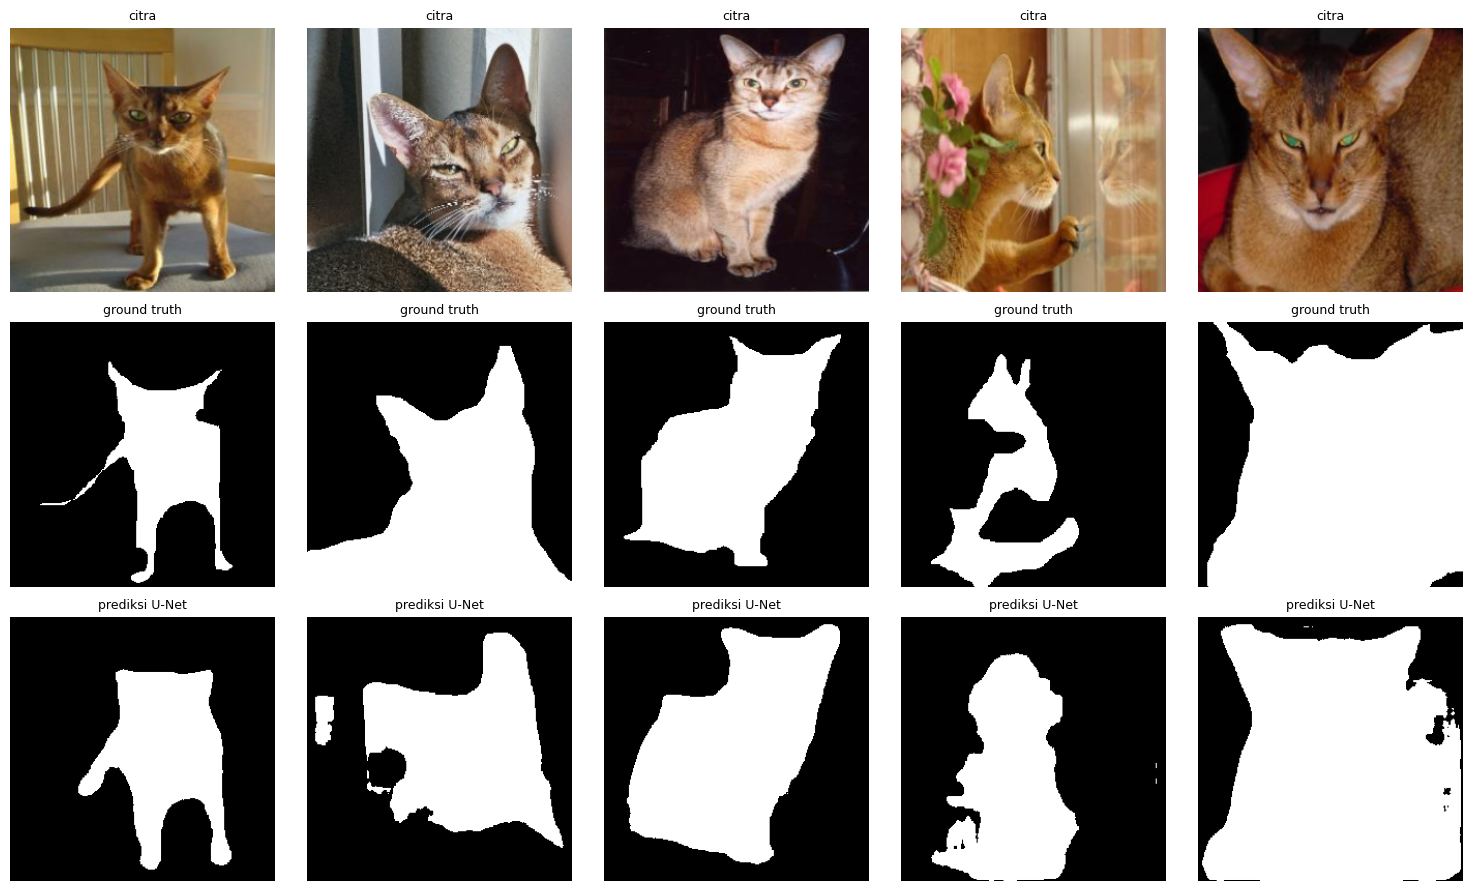

In [6]:
# === D3.1 Fungsi metrik dan evaluasi ===
@torch.no_grad()
def evaluasi(model, forward, thr=0.5):
    model.eval()
    TP = FP = FN = TN = 0
    iou_per_citra = []
    for x, y, v in dl_test:
        x, y, v = x.to(DEVICE), y.to(DEVICE), v.to(DEVICE)
        pred = (torch.sigmoid(forward(model, x)) > thr).float()

        tp = (pred * y * v).sum(dim=(1, 2, 3))
        fp = (pred * (1 - y) * v).sum(dim=(1, 2, 3))
        fn = ((1 - pred) * y * v).sum(dim=(1, 2, 3))
        tn = ((1 - pred) * (1 - y) * v).sum(dim=(1, 2, 3))

        TP += tp.sum().item(); FP += fp.sum().item()
        FN += fn.sum().item(); TN += tn.sum().item()
        iou_per_citra += (tp / (tp + fp + fn).clamp_min(1)).tolist()

    iou_fg = TP / (TP + FP + FN); iou_bg = TN / (TN + FN + FP)
    return {"IoU hewan": iou_fg, "IoU latar": iou_bg, "mIoU": (iou_fg + iou_bg) / 2,
            "Dice": 2 * TP / (2 * TP + FP + FN), "PixelAcc": (TP + TN) / (TP + TN + FP + FN),
            "iou_per_citra": iou_per_citra}

def ringkas(m): return {k: round(v, 4) for k, v in m.items() if k != "iou_per_citra"}

HASIL = {}
HASIL["U-Net (dari nol)"] = evaluasi(unet, fwd_unet)
print(ringkas(HASIL["U-Net (dari nol)"]))

# === D3.2 Visualisasi prediksi U-Net ===
@torch.no_grad()
def prediksi(model, forward, idx):
    x = torch.stack([ds_test[i][0] for i in idx]).to(DEVICE)
    return (torch.sigmoid(forward(model, x)) > 0.5).float().cpu()

idx_vis = [0, 1, 2, 3, 4]
p_unet = prediksi(unet, fwd_unet, idx_vis)

fig, ax = plt.subplots(3, len(idx_vis), figsize=(3 * len(idx_vis), 9))
for j, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[0, j].imshow(denorm(x)); ax[0, j].set_title("citra", fontsize=9)
    ax[1, j].imshow(y[0], cmap="gray"); ax[1, j].set_title("ground truth", fontsize=9)
    ax[2, j].imshow(p_unet[j, 0], cmap="gray"); ax[2, j].set_title("prediksi U-Net", fontsize=9)
    for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d3_prediksi_unet.png", dpi=120); plt.show()

#Praktikum D4 (DeepLabV3)

In [7]:
# === D4.1 Muat DeepLabV3 pra-latih dan ganti kepala klasifikasi ===
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large, DeepLabV3_MobileNet_V3_Large_Weights

set_seed(42)
dlv3 = deeplabv3_mobilenet_v3_large(weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT)
dlv3.classifier[4] = nn.Conv2d(256, 1, kernel_size=1) # 21 kelas VOC -> 1 kanal
dlv3.aux_classifier = None
dlv3 = dlv3.to(DEVICE)

fwd_dlv3 = lambda m, x: m(x)["out"]

groups = [{"params": dlv3.backbone.parameters(), "lr": 1e-4},
          {"params": dlv3.classifier.parameters(), "lr": 1e-3}]

hist_dlv3 = latih(dlv3, fwd_dlv3, CFG["EP_DLV3"], 1e-3, "DeepLabV3-MobileNetV3 (pra-latih)", param_groups=groups)
HASIL["DeepLabV3-MobileNetV3 (pra-latih)"] = evaluasi(dlv3, fwd_dlv3)
print(ringkas(HASIL["DeepLabV3-MobileNetV3 (pra-latih)"]))

Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth


100%|██████████| 42.3M/42.3M [00:00<00:00, 107MB/s]


[DeepLabV3-MobileNetV3 (pra-latih)] epoch 1/6 loss latih 0.1819 loss uji 0.1294 (23s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 2/6 loss latih 0.0925 loss uji 0.1249 (47s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 3/6 loss latih 0.0717 loss uji 0.1026 (70s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 4/6 loss latih 0.0588 loss uji 0.1059 (93s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 5/6 loss latih 0.0525 loss uji 0.1118 (116s)
[DeepLabV3-MobileNetV3 (pra-latih)] epoch 6/6 loss latih 0.0448 loss uji 0.1033 (139s)
{'IoU hewan': 0.9535, 'IoU latar': 0.9752, 'mIoU': 0.9644, 'Dice': 0.9762, 'PixelAcc': 0.9836}


#Praktikum D5 (SegFormer-B0)

config.json:   0%|          | 0.00/70.0k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 14.4MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[SegFormer-B0 (pra-latih)] epoch 1/6 loss latih 0.3172 loss uji 0.1589 (28s)
[SegFormer-B0 (pra-latih)] epoch 2/6 loss latih 0.1414 loss uji 0.1436 (55s)
[SegFormer-B0 (pra-latih)] epoch 3/6 loss latih 0.1050 loss uji 0.1365 (83s)
[SegFormer-B0 (pra-latih)] epoch 4/6 loss latih 0.1024 loss uji 0.1643 (110s)
[SegFormer-B0 (pra-latih)] epoch 5/6 loss latih 0.0921 loss uji 0.1246 (137s)
[SegFormer-B0 (pra-latih)] epoch 6/6 loss latih 0.0693 loss uji 0.1148 (165s)
{'IoU hewan': 0.9416, 'IoU latar': 0.9685, 'mIoU': 0.955, 'Dice': 0.9699, 'PixelAcc': 0.9791}


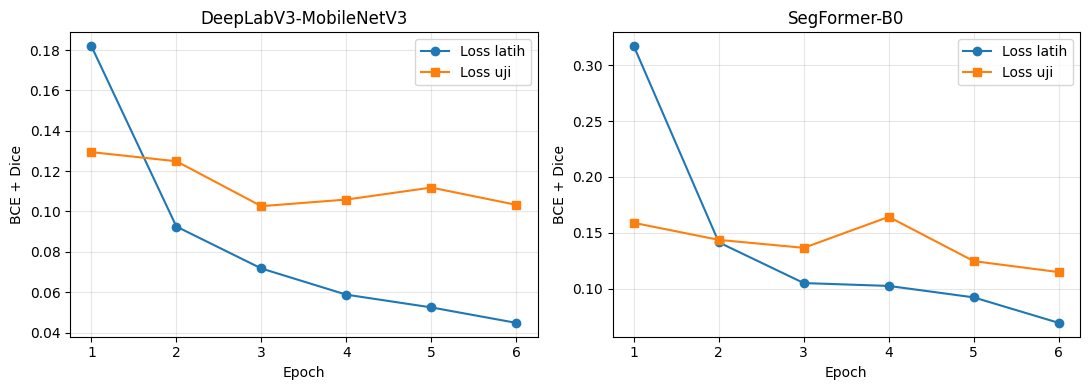

In [8]:
# === D5.1 Muat SegFormer-B0 dan latih ===
import transformers
from transformers import SegformerForSemanticSegmentation
transformers.logging.set_verbosity_error()

set_seed(42)
segf = SegformerForSemanticSegmentation.from_pretrained("nvidia/mit-b0", num_labels=1).to(DEVICE)

def fwd_segf(m, x):
    logit = m(pixel_values=x).logits
    return F.interpolate(logit, size=x.shape[-2:], mode="bilinear", align_corners=False)

hist_segf = latih(segf, fwd_segf, CFG["EP_SEGF"], 3e-4, "SegFormer-B0 (pra-latih)")
HASIL["SegFormer-B0 (pra-latih)"] = evaluasi(segf, fwd_segf)
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))

# === D5.2 Kurva loss model pra-latih ===
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nama, h) in zip(ax, [("DeepLabV3-MobileNetV3", hist_dlv3), ("SegFormer-B0", hist_segf)]):
    ep = range(1, len(h["train"]) + 1)
    a.plot(ep, h["train"], "o-", label="Loss latih")
    a.plot(ep, h["test"], "s-", label="Loss uji")
    a.set_title(nama); a.set_xlabel("Epoch"); a.set_ylabel("BCE + Dice")
    a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d5_kurva_pralatih.png", dpi=120); plt.show()

#Praktikum D6 (Analisis & Evaluasi Tabel)

                            Model  IoU hewan  IoU latar   mIoU   Dice  PixelAcc  Parameter (juta)  Waktu latih (s)
                 U-Net (dari nol)     0.8206     0.8979 0.8592 0.9014    0.9304              7.76            750.4
DeepLabV3-MobileNetV3 (pra-latih)     0.9535     0.9752 0.9644 0.9762    0.9836             11.02            138.8
         SegFormer-B0 (pra-latih)     0.9416     0.9685 0.9550 0.9699    0.9791              3.71            164.6


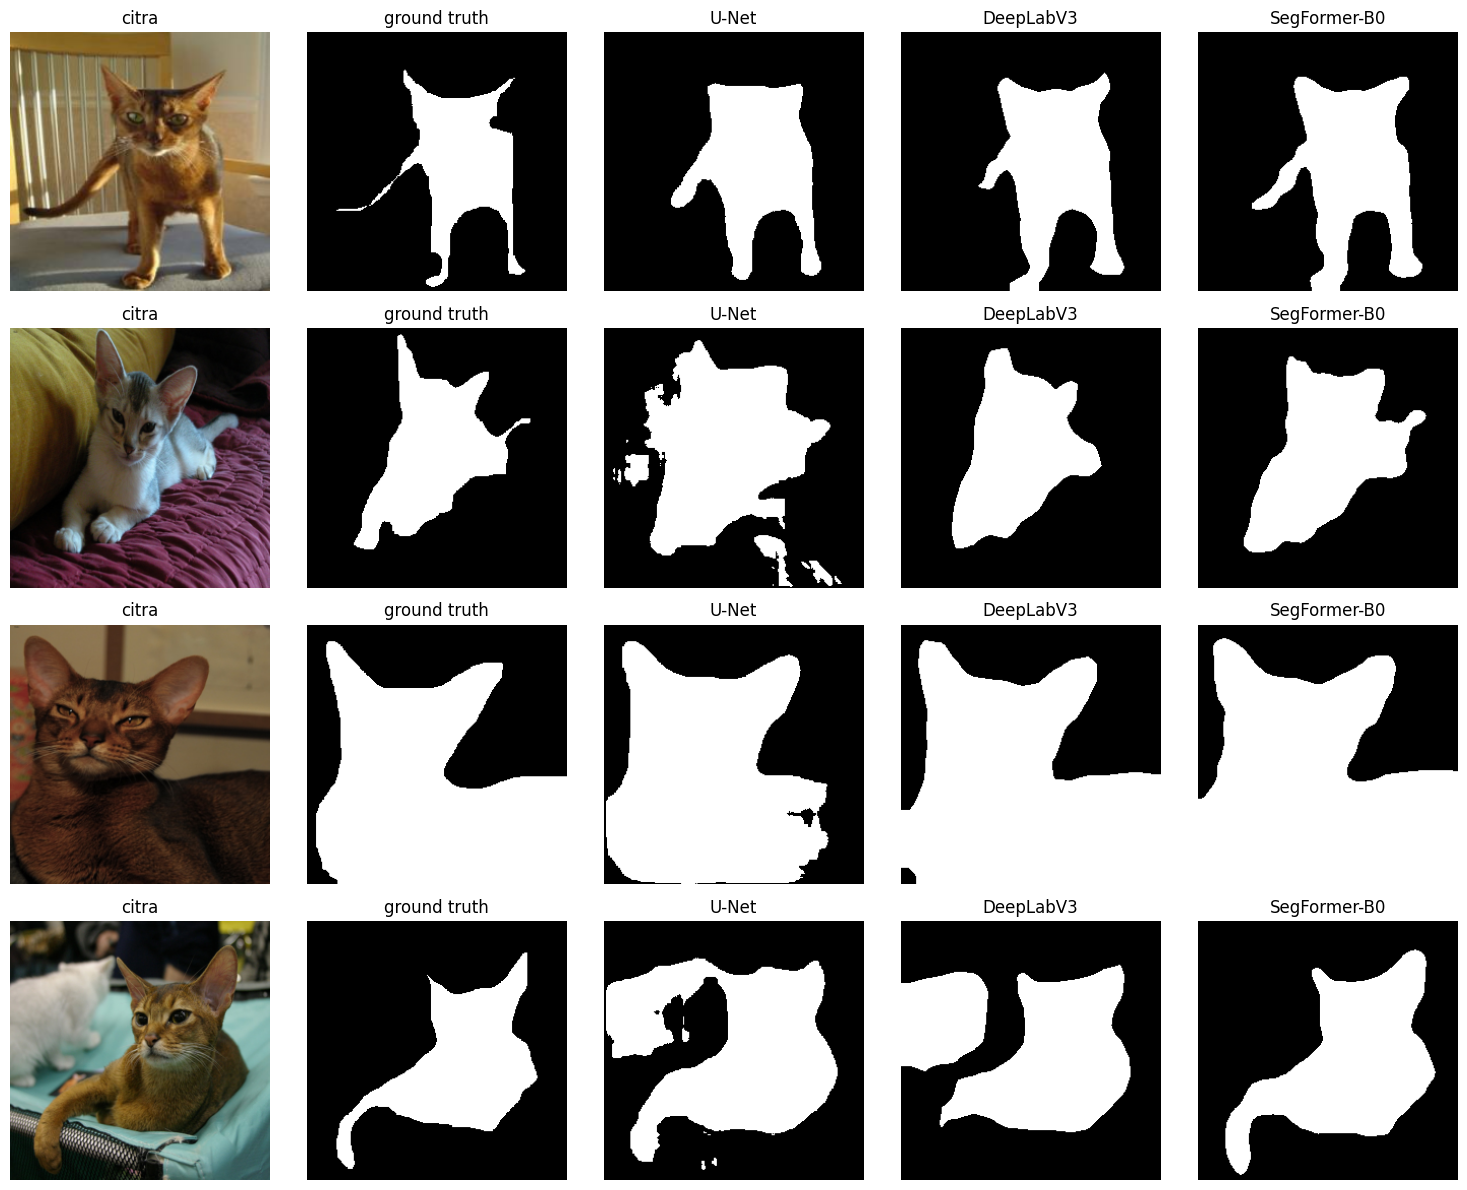

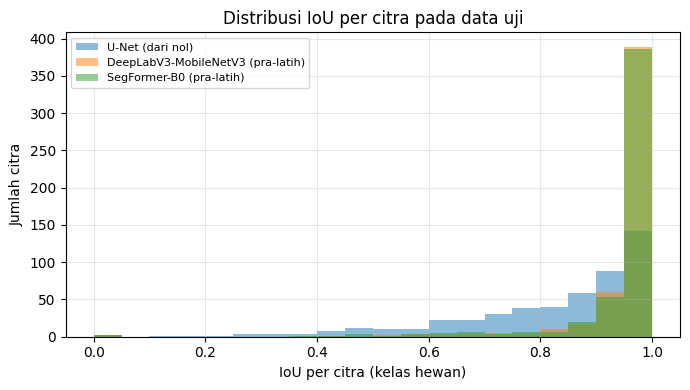

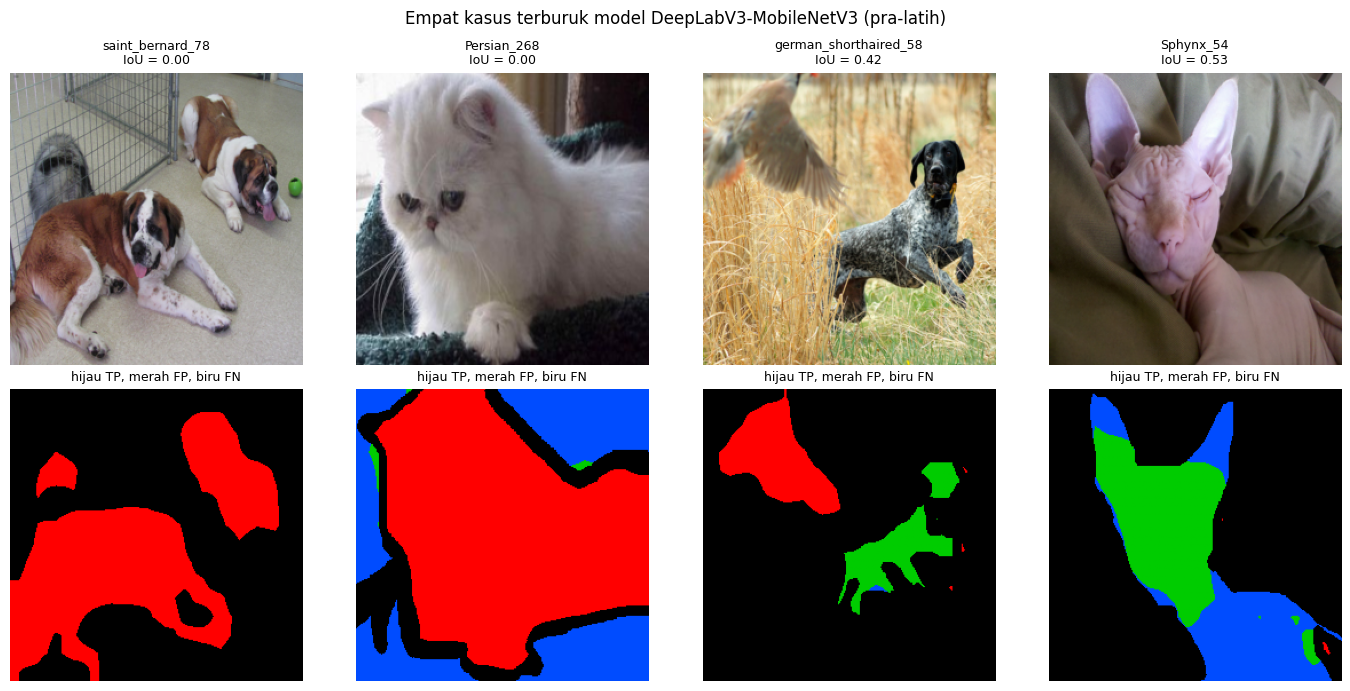

Model terbaik: DeepLabV3-MobileNetV3 (pra-latih) | IoU terendah: [0.0, 0.005, 0.42, 0.533]


In [10]:
# === D6.1 Tabel perbandingan ===
import pandas as pd
import json

param = {"U-Net (dari nol)": unet, "DeepLabV3-MobileNetV3 (pra-latih)": dlv3, "SegFormer-B0 (pra-latih)": segf}
tabel = pd.DataFrame([
    {"Model": k, **ringkas(v),
     "Parameter (juta)": round(sum(p.numel() for p in param[k].parameters()) / 1e6, 2),
     "Waktu latih (s)": round(WAKTU[k], 1)}
    for k, v in HASIL.items()
])
print(tabel.to_string(index=False))
tabel.to_csv(f"{FIG_DIR}/js05_tabel_hasil.csv", index=False)

with open(f"{FIG_DIR}/js05_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH",
               "cfg": CFG, "hasil": {k: ringkas(v) for k, v in HASIL.items()},
               "waktu_detik": WAKTU}, f, indent=2)

# === D6.2 Contoh prediksi ketiga model ===
# Di sini kita gunakan nama pendek hanya untuk judul gambar
model_fwd = [("U-Net", unet, fwd_unet), ("DeepLabV3", dlv3, fwd_dlv3), ("SegFormer-B0", segf, fwd_segf)]
idx_vis = [0, 5, 10, 15]
fig, ax = plt.subplots(len(idx_vis), 5, figsize=(15, 3 * len(idx_vis)))
preds = {n: prediksi(m, f, idx_vis) for n, m, f in model_fwd}

for r, i in enumerate(idx_vis):
    x, y, v = ds_test[i]
    ax[r, 0].imshow(denorm(x)); ax[r, 1].imshow(y[0], cmap="gray")
    ax[r, 0].set_title("citra"); ax[r, 1].set_title("ground truth")
    for c, (n, _, _) in enumerate(model_fwd):
        ax[r, c + 2].imshow(preds[n][r, 0], cmap="gray"); ax[r, c + 2].set_title(n)
    for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_perbandingan.png", dpi=110); plt.show()

# === D6.3 Analisis kesalahan: distribusi IoU per citra dan kasus terburuk ===
plt.figure(figsize=(7, 4))
for n, m in HASIL.items():
    plt.hist(m["iou_per_citra"], bins=20, range=(0, 1), alpha=.5, label=n)
plt.xlabel("IoU per citra (kelas hewan)"); plt.ylabel("Jumlah citra")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.title("Distribusi IoU per citra pada data uji")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_histogram_iou.png", dpi=120); plt.show()

terbaik = max(HASIL, key=lambda k: HASIL[k]["mIoU"])

# PERBAIKAN: Pastikan dictionary lookup menggunakan nama panjang yang persis sama dengan keys di HASIL
mdl, fw = {n: (m, f) for n, m, f in [
    ("U-Net (dari nol)", unet, fwd_unet),
    ("DeepLabV3-MobileNetV3 (pra-latih)", dlv3, fwd_dlv3),
    ("SegFormer-B0 (pra-latih)", segf, fwd_segf)
]}[terbaik]

iou = np.array(HASIL[terbaik]["iou_per_citra"])
buruk = np.argsort(iou)[:4].tolist()
pb = prediksi(mdl, fw, buruk)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, i in enumerate(buruk):
    x, y, v = ds_test[i]; p = pb[j, 0]; g = y[0]; val = v[0]
    peta = np.zeros((*g.shape, 3))
    peta[((p == 1) & (g == 1) & (val == 1)).numpy()] = [0, .8, 0] # Hijau TP
    peta[((p == 1) & (g == 0) & (val == 1)).numpy()] = [1, 0, 0]  # Merah FP
    peta[((p == 0) & (g == 1) & (val == 1)).numpy()] = [0, .3, 1] # Biru FN

    ax[0, j].imshow(denorm(x))
    ax[0, j].set_title(f"{ID_TEST[i]}\nIoU = {iou[i]:.2f}", fontsize=9)
    ax[1, j].imshow(peta)
    ax[1, j].set_title("hijau TP, merah FP, biru FN", fontsize=9)
    for a in ax.ravel(): a.axis("off")
plt.suptitle(f"Empat kasus terburuk model {terbaik}")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js05_d6_kasus_terburuk.png", dpi=110); plt.show()

print("Model terbaik:", terbaik, "| IoU terendah:", np.round(iou[buruk], 3).tolist())

#Tugas Nomor 4: Eksperimen Perbaikan Model

In [11]:
# === PENUGASAN TUGAS 4: Eksperimen Perbaikan Model Terbaik (SegFormer) ===
# Eksperimen: Menambah 4 epoch tambahan pada model SegFormer-B0

print("--- Memulai Eksperimen Tugas 4 ---")
print("Melatih ulang model SegFormer-B0 dengan tambahan 4 epoch...")

# Melanjutkan pelatihan pada model 'segf' yang sudah ada
hist_eksperimen = latih(segf, fwd_segf, epochs=4, lr=1e-4, nama="SegFormer-B0 (Eksperimen Epoch)")

# Evaluasi hasil setelah eksperimen penambahan epoch
HASIL["SegFormer-B0 (Eksperimen)"] = evaluasi(segf, fwd_segf)

# Cetak perbandingan hasilnya
print("\n--- PERBANDINGAN METRIK ---")
print("SEBELUM Eksperimen (SegFormer Awal):")
print(ringkas(HASIL["SegFormer-B0 (pra-latih)"]))
print("\nSESUDAH Eksperimen (Tambah 4 Epoch):")
print(ringkas(HASIL["SegFormer-B0 (Eksperimen)"]))

--- Memulai Eksperimen Tugas 4 ---
Melatih ulang model SegFormer-B0 dengan tambahan 4 epoch...
[SegFormer-B0 (Eksperimen Epoch)] epoch 1/4 loss latih 0.0502 loss uji 0.1044 (26s)
[SegFormer-B0 (Eksperimen Epoch)] epoch 2/4 loss latih 0.0446 loss uji 0.1006 (52s)
[SegFormer-B0 (Eksperimen Epoch)] epoch 3/4 loss latih 0.0389 loss uji 0.0959 (78s)
[SegFormer-B0 (Eksperimen Epoch)] epoch 4/4 loss latih 0.0382 loss uji 0.1001 (105s)

--- PERBANDINGAN METRIK ---
SEBELUM Eksperimen (SegFormer Awal):
{'IoU hewan': 0.9416, 'IoU latar': 0.9685, 'mIoU': 0.955, 'Dice': 0.9699, 'PixelAcc': 0.9791}

SESUDAH Eksperimen (Tambah 4 Epoch):
{'IoU hewan': 0.9524, 'IoU latar': 0.975, 'mIoU': 0.9637, 'Dice': 0.9756, 'PixelAcc': 0.9833}


#Tugas Nomor 5: Uji Coba Foto Peliharaan Sendiri

--- Memulai Tugas 5 ---
Silakan klik tombol 'Choose Files' di bawah ini untuk mengunggah 3 foto hewan peliharaan Anda:


Saving anjing1.jpg to anjing1.jpg
Saving kucing2.jpg to kucing2.jpg
Saving kucing1.jpg to kucing1.jpg


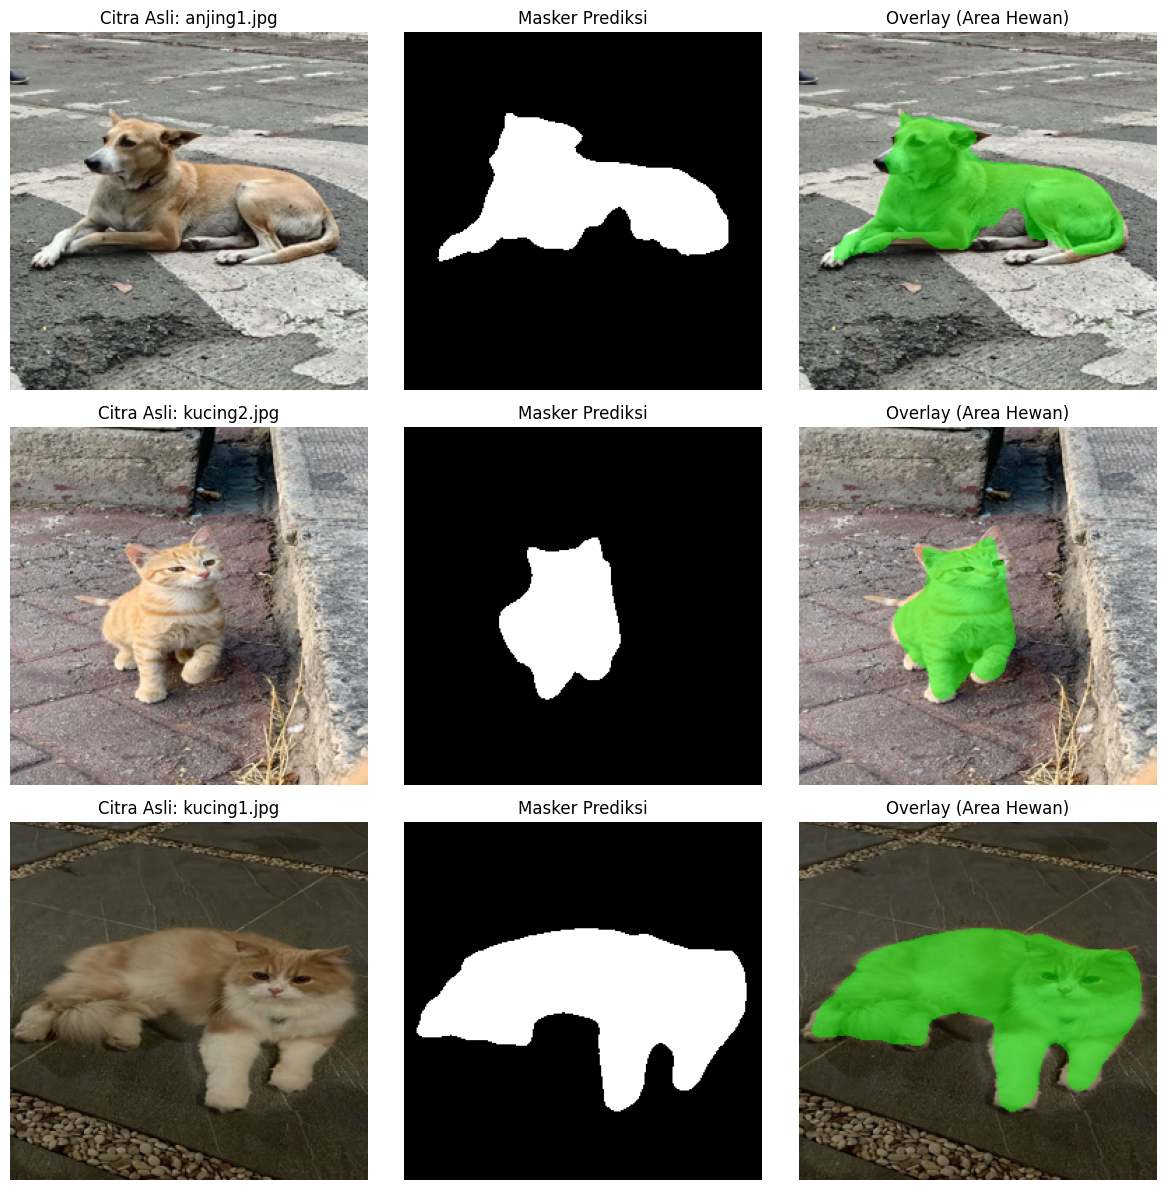

In [12]:
# === PENUGASAN TUGAS 5: Segmentasi Foto Hewan Peliharaan Sendiri ===
from google.colab import files
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch

print("--- Memulai Tugas 5 ---")
print("Silakan klik tombol 'Choose Files' di bawah ini untuk mengunggah 3 foto hewan peliharaan Anda:")
uploaded = files.upload()

if len(uploaded) > 0:
    fig, ax = plt.subplots(len(uploaded), 3, figsize=(12, 4 * len(uploaded)))

    # Penanganan jika tidak sengaja hanya mengunggah 1 foto
    if len(uploaded) == 1:
        ax = [ax]

    for idx, filename in enumerate(uploaded.keys()):
        # 1. Buka foto dan sesuaikan ukurannya dengan input model
        img = Image.open(filename).convert("RGB").resize((CFG["IMG"], CFG["IMG"]))
        img_np = np.array(img)

        # 2. Normalisasi citra menjadi Tensor
        x = (torch.from_numpy(img_np).permute(2, 0, 1).float() / 255.0 - MEAN) / STD
        x = x.unsqueeze(0).to(DEVICE)

        # 3. Lakukan prediksi segmentasi menggunakan SegFormer
        with torch.no_grad():
            pred = (torch.sigmoid(fwd_segf(segf, x)) > 0.5).float().cpu().squeeze()

        # 4. Buat efek overlay (Area prediksi hewan diwarnai hijau semi-transparan)
        mask = pred.numpy()
        overlay = img_np.copy()
        overlay[mask == 1] = overlay[mask == 1] * 0.5 + np.array([0, 255, 0]) * 0.5

        # 5. Tampilkan gambar berdampingan
        ax[idx, 0].imshow(img_np); ax[idx, 0].set_title(f"Citra Asli: {filename}")
        ax[idx, 1].imshow(mask, cmap="gray"); ax[idx, 1].set_title("Masker Prediksi")
        ax[idx, 2].imshow(overlay.astype(np.uint8)); ax[idx, 2].set_title("Overlay (Area Hewan)")
        for a in ax[idx]: a.axis("off")

    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/js05_tugas5_foto_sendiri.png", dpi=120)
    plt.show()
else:
    print("Tidak ada foto yang diunggah. Silakan jalankan ulang sel ini.")